# Customer Segmentation

> **Sample data disclaimer:** This notebook uses sample data, not the original business data. Cluster profiles and all reported values are specific to this sample and may differ when original data is used.
___

## 1. Library Import


In [7]:
import sys
sys.path.append("..")

In [8]:
import os
import pandas as pd
import numpy as np
from datetime import timedelta
import matplotlib.pyplot as plt
import seaborn as sns
from plotly.subplots import make_subplots
import plotly.graph_objects as go
import plotly.express as px
import plotly.io as pio
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
import datetime
from pathlib import Path

In [9]:
path = "../data/sample/"
output_dir = Path("../charts_and_figures/customer_segmentation")
output_dir.mkdir(exist_ok=True)
sns.set_style("darkgrid")

In [10]:
from src.data import load_raw_tables

customers_df, products_df, sales_df = load_raw_tables(str(path))

## 2. Data Assessment

The source tables are cleaned and consolidated into the dataset used for segmentation.


In [11]:
sales_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 129032 entries, 0 to 129031
Data columns (total 7 columns):
 #   Column         Non-Null Count   Dtype 
---  ------         --------------   ----- 
 0   SALE_ID        129032 non-null  int64 
 1   SALE_DATE      129032 non-null  object
 2   CUSTOMER_ID    129032 non-null  int64 
 3   PRODUCT_ID     129032 non-null  int64 
 4   QUANTITY       129032 non-null  Int64 
 5   SALE_CATEGORY  129032 non-null  string
 6   BRANCH         129032 non-null  int64 
dtypes: Int64(1), int64(4), object(1), string(1)
memory usage: 7.0+ MB


In [12]:
sales_df['SALE_DATE'] = pd.to_datetime(sales_df['SALE_DATE'], format='%Y/%m/%d', errors='coerce')
sales_df['yemo'] = sales_df['SALE_DATE'].apply(lambda x: datetime.date(x.year, x.month, 1))

sales_df = pd.merge(sales_df,products_df,how='left',on=['PRODUCT_ID'])

In [13]:
sales_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 129032 entries, 0 to 129031
Data columns (total 13 columns):
 #   Column         Non-Null Count   Dtype         
---  ------         --------------   -----         
 0   SALE_ID        129032 non-null  int64         
 1   SALE_DATE      129032 non-null  datetime64[ns]
 2   CUSTOMER_ID    129032 non-null  int64         
 3   PRODUCT_ID     129032 non-null  int64         
 4   QUANTITY       129032 non-null  Int64         
 5   SALE_CATEGORY  129032 non-null  string        
 6   BRANCH         129032 non-null  int64         
 7   yemo           129032 non-null  object        
 8   UNIT           129032 non-null  object        
 9   LEVEL_1        110190 non-null  object        
 10  LEVEL_2        110190 non-null  object        
 11  LEVEL_3        110190 non-null  object        
 12  LEVEL_4        97727 non-null   object        
dtypes: Int64(1), datetime64[ns](1), int64(4), object(6), string(1)
memory usage: 12.9+ MB


### 2.1 Transaction Data Consolidation


In [14]:
# Aggregate by day
day_sales         = sales_df.groupby(['SALE_DATE','yemo','CUSTOMER_ID']).agg({'QUANTITY':['sum','count']}).reset_index()
day_sales.columns = day_sales.columns.droplevel(0)
day_sales.columns = ['SALE_DATE','yemo','CUSTOMER_ID','quantity','n_prod']

In [15]:
# Aggregate by month
month_sales = day_sales.groupby(['yemo','CUSTOMER_ID']).agg({'quantity':['sum','count'],'n_prod':['mean']}).reset_index()
month_sales.columns = month_sales.columns.droplevel(0)
month_sales.columns = ['yemo','CUSTOMER_ID','quantity','freq_int_mes','n_prod']

In [16]:
# Aggregate by customer
customer_sales = month_sales.groupby(['CUSTOMER_ID']).agg({'yemo':['max','min'],
                                                       'quantity':['sum'],
                                                       'n_prod':['mean'],
                                                       'freq_int_mes':['sum','mean','count']}).reset_index()

customer_sales.columns = customer_sales.columns.droplevel(0)
customer_sales.columns = ['CUSTOMER_ID','last_purchase','first_purchase','quantity','n_prod','n_pur','mon_freq','n_mon']

In [17]:
# Calculate features
customer_sales['today'] = datetime.date(2026,8,17)

customer_sales['recency']      = customer_sales.apply(lambda x: (x['today'].year    - x['last_purchase'].year) * 12   + (x['today'].month    - x['last_purchase'].month ),axis=1)
customer_sales['time_relation'] = customer_sales.apply(lambda x: (x['last_purchase'].year - x['first_purchase'].year) * 12 + (x['last_purchase'].month - x['first_purchase'].month ),axis=1)
customer_sales['retention'] = customer_sales.apply(lambda x: (x['today'].year    - x['first_purchase'].year) * 12 + (x['today'].month    - x['first_purchase'].month ),axis=1)

### 2.2 Purchase Share by Channel


In [18]:
# Consolidate by store
store_sale = sales_df.groupby(['CUSTOMER_ID', 'SALE_CATEGORY'], as_index=False).agg(
    qnty=('QUANTITY', 'sum'),
    n_pur=('SALE_DATE', 'count')  # Conta o número de compras/registros
)

In [19]:
store_sale.head()

,CUSTOMER_ID,SALE_CATEGORY,qnty,n_pur
0,1,STORE,8,6
1,2,STORE,29,24
2,3,STORE,17,17
3,4,STORE,9,5
4,5,CLINIC,5,5


In [20]:
# 1. Initial grouby - building base
store_sale = sales_df.groupby(['CUSTOMER_ID', 'SALE_CATEGORY'], as_index=False).agg(
    qnty=('QUANTITY', 'sum'),
    n_pur=('SALE_DATE', 'nunique')) 

# 2. Removing spaces from SALE_CATEGORY
store_sale['SALE_CATEGORY'] = store_sale['SALE_CATEGORY'].str.strip()

# 3. Mapping SALE_CATEGORY to new column names
category_map = {
    'CLINIC': 'clinic_npur',
    'GROOMING': 'grooming_npur',
    'STORE': 'store_npur',
    'DIGITAL': 'dig_npur',
    'E-COMMERCE': 'ecomm_npur',
}

# 4. Pivoting the DataFrame to have SALE_CATEGORY as columns
store_sale = (
    sales_df
    .assign(SALE_CATEGORY=lambda df: df['SALE_CATEGORY'].str.strip())
    .pivot_table(
        index='CUSTOMER_ID',
        columns='SALE_CATEGORY',
        values='SALE_DATE',
        aggfunc='nunique',
        fill_value=0
    )
    .reset_index()
    .rename(columns=category_map)
)
store_sale.columns.name = None

# 5. Final adjustment of headers and renaming
store_sale.columns.name = None
store_sale = store_sale.rename(columns=category_map)

In [21]:
# Share of purchases by category
category_cols = [col for col in category_map.values() if col in store_sale.columns]
total_purchases = store_sale[category_cols].sum(axis=1)

In [22]:
store_sale_share = store_sale.copy()
store_sale_share[category_cols] = (
    store_sale_share[category_cols]
    .div(total_purchases, axis=0)
    .fillna(0)
)

### 2.3 Combine the Customer Dataset and Final Adjustments


Description of engineered features

* **last_purchase:** Most recent purchase date
* **first_purchase:** First purchase date
* **quantity:** Total quantity of items purchased
* **n_prod:** Average number of products per purchase
* **n_pur:** Total number of customer purchases (at most one per day)
* **mon_freq:** Average monthly purchase frequency
* **n_mon:** Number of months with purchases
* **recency:** Months since the most recent purchase
* **time_relation:** Months between the first and most recent purchase
* **retention:** Months since the first purchase
* **clinic_npur:** Share of purchases made at clinics
* **grooming_npur:** Share of purchases made through grooming services
* **store_npur:** Share of purchases made in stores
* **dig_npur:** Share of purchases made through digital marketplaces
* **ecomm_npur:** Share of purchases made through e-commerce
* **qnty_pur:** Average quantity of items per purchase


In [23]:
# Combine the datasets
final_df = pd.merge(customer_sales,store_sale_share,how='left',on=['CUSTOMER_ID'])

In [24]:
# Adjust the fields
final_df['qnty_pur'] = final_df['quantity']/final_df['n_pur']
final_df = final_df.drop(['today'],axis=1)

In [25]:
final_df.head()

,CUSTOMER_ID,last_purchase,first_purchase,quantity,n_prod,n_pur,mon_freq,n_mon,recency,time_relation,retention,clinic_npur,dig_npur,ecomm_npur,grooming_npur,store_npur,qnty_pur
0,1,2021-07-01,2020-01-01,8,1.5,4,1.0,4,61,18,79,0.0,0.0,0.0,0.0,1.0,2.0
1,2,2021-07-01,2020-02-01,29,2.25,11,1.1,10,61,17,78,0.0,0.0,0.0,0.0,1.0,2.636364
2,3,2021-05-01,2020-05-01,17,1.761905,9,1.285714,7,63,12,75,0.0,0.0,0.0,0.0,1.0,1.888889
3,4,2021-02-01,2020-11-01,9,2.5,2,1.0,2,66,3,69,0.0,0.0,0.0,0.0,1.0,4.5
4,5,2021-06-01,2020-02-01,25,2.214286,10,1.428571,7,62,16,78,0.2,0.0,0.0,0.1,0.7,2.5


## 3. Feature Analysis

This section explores the engineered features.


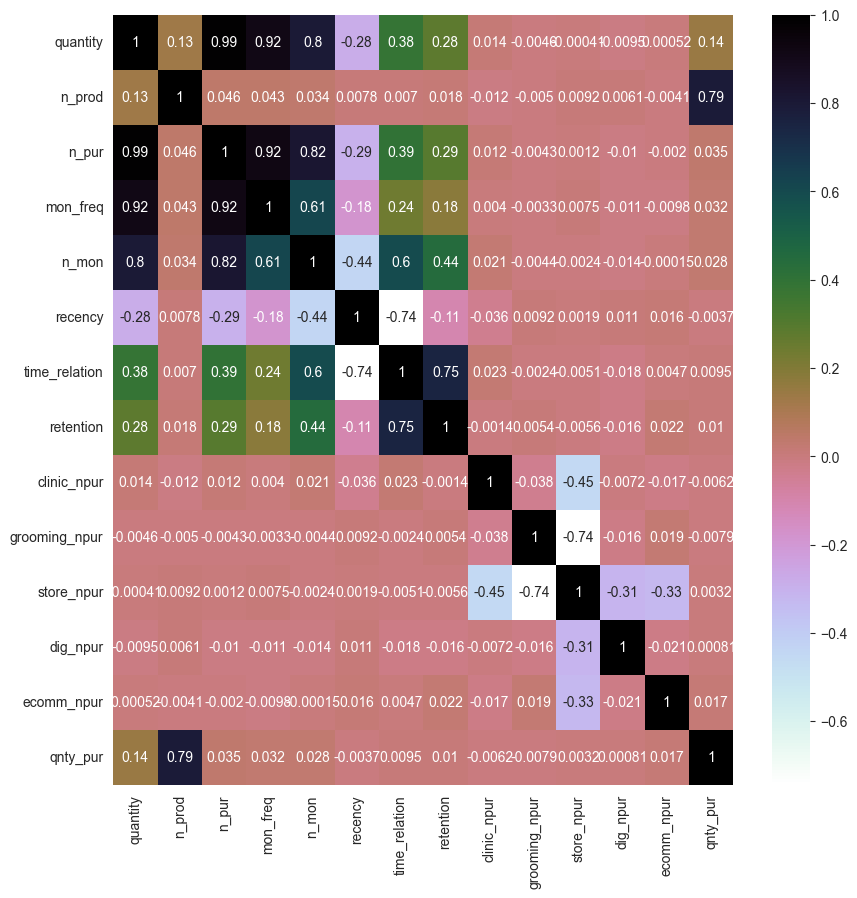

In [26]:
# Evaluate correlations between features
plt.figure(figsize=(10,10))
sns.heatmap(final_df[['quantity', 'n_prod','n_pur', 'mon_freq', 'n_mon', 'recency',
       'time_relation', 'retention', 'clinic_npur','grooming_npur',
       'store_npur','dig_npur', 'ecomm_npur','qnty_pur']].corr(),annot=True,cmap='cubehelix_r')

plt.show()

In [27]:
#analyzed_variable = 'quantity'
#analyzed_variable = 'n_prod'
#analyzed_variable = 'n_pur'
#analyzed_variable = 'mon_freq'
#analyzed_variable = 'n_mon'
analyzed_variable = 'recency'
#analyzed_variable = 'time_relation'
#analyzed_variable = 'retention'
#analyzed_variable = 'clinic_npur'
#analyzed_variable = 'grooming_npur'
#analyzed_variable = 'store_npur'
#analyzed_variable = 'dig_npur'
#analyzed_variable = 'ecomm_npur'
#analyzed_variable = 'qnty_pur'

fig = px.box(final_df, x=analyzed_variable)
fig.update_traces(orientation='h')
fig.update_layout(
    xaxis={'title': analyzed_variable},
    yaxis={'title': analyzed_variable, 'showline': False, 'ticks': ''}
)
fig.show()

## 4. Clustering

This section applies customer clustering.


### 4.1 Feature Selection


In [28]:
# Customer dataset with selected clustering features
customers = final_df[['CUSTOMER_ID','n_prod','qnty_pur','mon_freq', 'n_mon', 'recency','store_npur']]

### 4.2 Feature Scaling


In [29]:
# Dataset used for clustering

df_cluster = customers.drop(['CUSTOMER_ID'],axis=1)

# Scale the features
std_data = StandardScaler().fit_transform(df_cluster)
df_cluster = pd.DataFrame(data=std_data, columns=df_cluster.columns, index=df_cluster.index)

df_cluster.describe()

,n_prod,qnty_pur,mon_freq,n_mon,recency,store_npur
count,4.998000e+03,4.998000e+03,4998.000000,4.998000e+03,4.998000e+03,4.998000e+03
mean,-9.084370e-16,-1.649119e-16,0.000000,9.382917e-17,3.333779e-16,-1.080457e-15
std,1.000100e+00,1.000100e+00,1.000100,1.000100e+00,1.000100e+00,1.000100e+00
min,-3.300957e+00,-3.136900e+00,-0.661561,-1.692854e+00,-7.961858e-01,-8.605369e+00
25%,-4.965104e-01,-6.133483e-01,-0.661561,-7.394342e-01,-7.961858e-01,-5.195331e-01
50%,-2.910258e-02,-6.132129e-02,-0.230057,-2.627245e-01,-4.359670e-01,1.992078e-01
75%,6.252684e-01,6.484277e-01,0.201448,4.523401e-01,2.844705e-01,8.281062e-01
max,5.112383e+00,8.219084e+00,11.695168,3.312599e+00,6.768408e+00,8.281062e-01


### 4.3 Select the Number of Clusters


In [30]:
# Run K-Means iterations for the elbow method

wcss = {}
for k in range(1, 26):
  print(k)
  kmeans = KMeans(n_clusters=k, init='k-means++', max_iter=200, random_state=3)
  kmeans.fit(df_cluster)
  wcss[k] = kmeans.inertia_

1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25


In [42]:
fig = make_subplots(
    rows=1,
    cols=1,
    subplot_titles=['Elbow Method'],
    shared_xaxes=True,
    shared_yaxes=False)


fig.add_trace(
    go.Scatter(
        x=list(wcss.keys()),
        y=list(wcss.values()),
        mode='lines+markers',
        textposition='top center',
        showlegend=False),
    row=1,
    col=1)

fig.update_xaxes(visible=True, title='No. of clusters',row=1, col=1)
fig.update_yaxes(visible=True, title='Cluster Inertia',row=1, col=1)

fig.update_layout(
  title='Ideal cluster number definition',
  showlegend=False,
  xaxis_showticklabels=True,
  height=400,
  width=800,
  xaxis = dict(
    tickmode = 'linear',
    tick0 = 0,
    dtick = 1))

fig.show()

### 4.4 K-Means Clustering


In [43]:
# Define the dataset to cluster
df_cluster_km = df_cluster.copy()

# Clustering
clus = KMeans(n_clusters=5, init='k-means++', max_iter=300,random_state=3)
clus.fit(df_cluster_km)

# Ajustando as colunas
df_cluster_km.loc[:, 'CLUSTER'] = clus.labels_
df_cluster_km.head()

,n_prod,qnty_pur,mon_freq,n_mon,recency,store_npur,CLUSTER
0,-1.898734,-1.244236,-0.661561,-0.977789,0.284470,0.828106,2
1,0.204601,-0.039814,-0.445809,0.452340,0.284470,0.828106,2
2,-1.164236,-1.454532,-0.045126,-0.262724,1.004908,0.828106,2
3,0.905713,3.487424,-0.661561,-1.454499,2.085564,0.828106,3
4,0.104443,-0.297904,0.263092,-0.262724,0.644689,-2.001936,2


In [33]:
# Add cluster labels to the customer dataset
customers = pd.concat([customers, df_cluster_km[['CLUSTER']]], axis=1)

## 5. Cluster Analysis

This section examines the characteristics of each cluster.


### 5.1 Volumetria

In [44]:
cluster_size = customers.groupby('CLUSTER', as_index=False)['CUSTOMER_ID'].count()
fig = px.bar(cluster_size, x="CLUSTER", y="CUSTOMER_ID", title="# Customers by Cluster", text_auto=True)
fig.update_layout(
    width=600,
    height=400,
    showlegend=False)
fig.show()

### 5.2 Boxplot

In [35]:
# Features used for clustering
cluster_variables = customers.set_index(['CUSTOMER_ID', 'CLUSTER']).columns.tolist()
print(f'Features: {cluster_variables}')

Features: ['n_prod', 'qnty_pur', 'mon_freq', 'n_mon', 'recency', 'store_npur']


In [45]:
# Analyze a feature by cluster

for cluster_variable in cluster_variables:
  fig = px.box(customers, x=cluster_variable, y='CLUSTER', points=False)
  fig.update_traces(orientation='h')
  fig.update_layout(
      title=f'Distribution of {cluster_variable} by Cluster',
      xaxis={'title': cluster_variable},
      yaxis={'title': 'Cluster', 'showline': False, 'ticks': ''}
  )

  fig.update_layout(
      width=800,
      height=400,
      showlegend=False)

  fig.show()

### 5.3 Parallel Coordenates

In [58]:
cluster_means = customers.groupby(['CLUSTER']).mean().reset_index()
cluster_means.head()

,CLUSTER,CUSTOMER_ID,n_prod,qnty_pur,mon_freq,n_mon,recency,store_npur,grooming_npur_x,clinic_npur_x,...,dig_npur_y,ecomm_npur_y,quantity_y,n_pur_y,grooming_npur,clinic_npur,dig_npur,ecomm_npur,quantity,n_pur
0,0,2480.222944,2.089448,2.504669,1.173272,4.458874,66.679654,0.907343,0.061467,0.012487,...,0.009121,0.009582,13.393939,5.285714,0.061467,0.012487,0.009121,0.009582,13.393939,5.285714
1,1,2538.005676,2.198619,2.674276,1.541063,13.547777,58.612110,0.913405,0.048998,0.020865,...,0.008326,0.008407,57.43614,21.459792,0.048998,0.020865,0.008326,0.008407,57.43614,21.459792
2,2,2449.978953,1.919514,2.292114,1.189405,6.651437,59.686345,0.913256,0.047706,0.020830,...,0.008316,0.009892,18.315708,7.934292,0.047706,0.020830,0.008316,0.009892,18.315708,7.934292
3,3,2544.829876,2.53006,3.179355,1.179681,6.47787,60.142462,0.911479,0.050263,0.021155,...,0.007800,0.009304,24.245505,7.688105,0.050263,0.021155,0.007800,0.009304,24.245505,7.688105
4,4,2517.694118,2.281408,2.769761,3.962372,21.070588,58.082353,0.912637,0.048826,0.020633,...,0.007817,0.010087,234.611765,84.247059,0.048826,0.020633,0.007817,0.010087,234.611765,84.247059


In [59]:
parallel_variables = ['n_prod','qnty_pur', 'mon_freq', 'n_mon','recency', 'store_npur']

In [60]:
# Coordenadas Paralelas
fig = px.parallel_coordinates(cluster_means[parallel_variables +['CLUSTER']], color="CLUSTER")
fig.update_layout(
    title={
        'text': "Cluster analysis",
        'y':1
        },
    height=500,
    width=1000)
fig.show()

In [55]:
# Coordenadas Paralelas
fig = px.parallel_coordinates(cluster_means[parallel_variables +['grooming_npur','clinic_npur','dig_npur', 'ecomm_npur','quantity','n_pur'] +['CLUSTER']], color="CLUSTER")
fig.update_layout(
    title={
        'text': "Cluster analysis",
        'y':1
        },
    height=500,
    width=1000)
fig.show()

### 5.4 Conclusions


Cluster Profiles (sample-data results)

**Cluster 0:**
- Smallest customer group in the saved sample run
- More items per purchase on average
- Lower quantity per purchase and lower total quantity
- Higher share of store purchases

**Cluster 1:**
- Second-largest group in the saved sample run
- Fewer items but higher quantity per purchase
- Lower monthly frequency and fewer active months
- Higher recency and greater use of grooming and clinic services

**Cluster 2:**
- Fewer items per purchase and lower monthly frequency
- Fewer active months and higher recency
- Mostly store purchases; the sample suggests lower engagement

**Cluster 3:**
- Largest group in the saved sample run
- Fewer items and lower quantity per purchase
- The sample suggests stronger engagement, with lower recency and more active months
- Higher share of store purchases

**Cluster 4:**
- Higher quantity per purchase and monthly frequency
- More active months and lower recency
- Purchases across stores and service channels

Cluster sizes and descriptions above summarize saved sample outputs. They may change with different sample data or the original business data. These behavioral features do not establish customer profitability or monetary lifetime value.
